# Qual é o melhor plano?

Você trabalha como analista para a empresa de telecomunicações Megaline. A empresa oferece aos clientes dois planos pré-pagos: Surf e Ultimate. O departamento comercial quer saber qual dos planos gera mais receita para ajustar o orçamento de publicidade.

Você vai realizar uma análise preliminar dos planos com base em uma pequena seleção de clientes. Você terá dados de 500 clientes da Megaline: que clientes são, de onde eles são, qual plano usam e o número de chamadas e mensagens realizadas em 2018. Seu trabalho é analisar o comportamento dos clientes e determinar qual plano pré-pago gera mais receita.


Meu trabalho aqui é identificar qual plano gera mais receita para a empresa, para direcionar o trabalho de marketing e aumentar o lucro da empresa. Vou ter que limpar os dados e corrigir os tipos, agregar o uso por usuário por mês, calcular a receita, executar as estatísticas descritivas e os histogramas e testar as duas hipóteses.

## Inicialização

In [ ]:
# Carregando todas as bibliotecas
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats as st


## Carregue os dados

In [ ]:
# Carregue os arquivos de dados em diferentes DataFrames
mg_calls = pd.read_csv('/datasets/megaline_calls.csv')
mg_internet = pd.read_csv('/datasets/megaline_internet.csv')
mg_messages = pd.read_csv('/datasets/megaline_messages.csv')
mg_plans = pd.read_csv('/datasets/megaline_plans.csv')
mg_users = pd.read_csv('/datasets/megaline_users.csv')

## Prepare os dados

Vou usar a info() para fazer a primeira analise dos dados

## Planos

In [ ]:
# Imprima informações gerais/resumo sobre o DataFrame dos planos

print('Plans')
print(mg_plans.info())




Plans
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   messages_included      2 non-null      int64  
 1   mb_per_month_included  2 non-null      int64  
 2   minutes_included       2 non-null      int64  
 3   usd_monthly_pay        2 non-null      int64  
 4   usd_per_gb             2 non-null      int64  
 5   usd_per_message        2 non-null      float64
 6   usd_per_minute         2 non-null      float64
 7   plan_name              2 non-null      object 
dtypes: float64(2), int64(5), object(1)
memory usage: 256.0+ bytes
None


In [ ]:
# Imprima uma amostra de dados dos planos

print('Plans')
print(mg_plans.head())



Plans
   messages_included  mb_per_month_included  minutes_included  \
0                 50                  15360               500   
1               1000                  30720              3000   

   usd_monthly_pay  usd_per_gb  usd_per_message  usd_per_minute plan_name  
0               20          10             0.03            0.03      surf  
1               70           7             0.01            0.01  ultimate  



Essa é uma tabela com informações dos planos para ser usada como base de calculo, e as colunas usd_monthly_pay e usd_per_gb precisam estar no tipo float

## Corrija os dados

In [ ]:
mg_plans['usd_monthly_pay'] =  mg_plans['usd_monthly_pay'].astype('float')
mg_plans['usd_per_gb'] =  mg_plans['usd_per_gb'].astype('float')

print(mg_plans.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   messages_included      2 non-null      int64  
 1   mb_per_month_included  2 non-null      int64  
 2   minutes_included       2 non-null      int64  
 3   usd_monthly_pay        2 non-null      float64
 4   usd_per_gb             2 non-null      float64
 5   usd_per_message        2 non-null      float64
 6   usd_per_minute         2 non-null      float64
 7   plan_name              2 non-null      object 
dtypes: float64(4), int64(3), object(1)
memory usage: 256.0+ bytes
None


## Enriqueça os dados

[Inclua fatores adicionais aos dados se você acredita que eles podem ser úteis.]

## Usuários

In [ ]:
# Imprima informações gerais/resumo sobre o DataFrame dos usuários


print('Users')
print(mg_users.info())


Users
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     500 non-null    int64 
 1   first_name  500 non-null    object
 2   last_name   500 non-null    object
 3   age         500 non-null    int64 
 4   city        500 non-null    object
 5   reg_date    500 non-null    object
 6   plan        500 non-null    object
 7   churn_date  34 non-null     object
dtypes: int64(2), object(6)
memory usage: 31.4+ KB
None


In [ ]:
# Imprima uma amostra de dados dos usuários

print('Users')
print(mg_users.head())
print()
print(mg_users.duplicated().sum())
print()
print(mg_users['plan'].unique())

Users
   user_id first_name  last_name  age                                   city  \
0     1000   Anamaria      Bauer   45  Atlanta-Sandy Springs-Roswell, GA MSA   
1     1001     Mickey  Wilkerson   28        Seattle-Tacoma-Bellevue, WA MSA   
2     1002     Carlee    Hoffman   36   Las Vegas-Henderson-Paradise, NV MSA   
3     1003   Reynaldo    Jenkins   52                          Tulsa, OK MSA   
4     1004    Leonila   Thompson   40        Seattle-Tacoma-Bellevue, WA MSA   

     reg_date      plan churn_date  
0  2018-12-24  ultimate        NaN  
1  2018-08-13      surf        NaN  
2  2018-10-21      surf        NaN  
3  2018-01-28      surf        NaN  
4  2018-05-23      surf        NaN  

0

['ultimate' 'surf']



Indentificamos  as colunas rage_date e churn_date que são datas que estão como obejeto, precisamos alterar e temos valores ausentes na coluna churn_date, que indica que o plano está em uso

### Corrija os dados

In [ ]:
mg_users['churn_date'] = pd.to_datetime(mg_users['churn_date'], format = '%Y-%m-%d')
mg_users['reg_date'] = pd.to_datetime(mg_users['reg_date'], format = '%Y-%m-%d')

print(mg_users.info())
print(mg_users.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   user_id     500 non-null    int64         
 1   first_name  500 non-null    object        
 2   last_name   500 non-null    object        
 3   age         500 non-null    int64         
 4   city        500 non-null    object        
 5   reg_date    500 non-null    datetime64[ns]
 6   plan        500 non-null    object        
 7   churn_date  34 non-null     datetime64[ns]
dtypes: datetime64[ns](2), int64(2), object(4)
memory usage: 31.4+ KB
None
   user_id first_name  last_name  age                                   city  \
0     1000   Anamaria      Bauer   45  Atlanta-Sandy Springs-Roswell, GA MSA   
1     1001     Mickey  Wilkerson   28        Seattle-Tacoma-Bellevue, WA MSA   
2     1002     Carlee    Hoffman   36   Las Vegas-Henderson-Paradise, NV MSA   
3     1003   Reynaldo

### Enriqueça os dados

[Inclua fatores adicionais aos dados se você acredita que eles podem ser úteis.]

In [ ]:
mg_users['ativo'] = mg_users['churn_date'].isna()

print(mg_users)

     user_id first_name   last_name  age  \
0       1000   Anamaria       Bauer   45   
1       1001     Mickey   Wilkerson   28   
2       1002     Carlee     Hoffman   36   
3       1003   Reynaldo     Jenkins   52   
4       1004    Leonila    Thompson   40   
..       ...        ...         ...  ...   
495     1495      Fidel      Sharpe   67   
496     1496      Ariel    Shepherd   49   
497     1497      Donte     Barrera   49   
498     1498       Scot  Williamson   51   
499     1499      Shena     Dickson   37   

                                          city   reg_date      plan  \
0        Atlanta-Sandy Springs-Roswell, GA MSA 2018-12-24  ultimate   
1              Seattle-Tacoma-Bellevue, WA MSA 2018-08-13      surf   
2         Las Vegas-Henderson-Paradise, NV MSA 2018-10-21      surf   
3                                Tulsa, OK MSA 2018-01-28      surf   
4              Seattle-Tacoma-Bellevue, WA MSA 2018-05-23      surf   
..                                         ..

## Chamadas

In [ ]:
# Imprima informações gerais/resumo sobre o DataFrame das chamadas

print('Calls')
print(mg_calls.info())

Calls
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 137735 entries, 0 to 137734
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   id         137735 non-null  object 
 1   user_id    137735 non-null  int64  
 2   call_date  137735 non-null  object 
 3   duration   137735 non-null  float64
dtypes: float64(1), int64(1), object(2)
memory usage: 4.2+ MB
None


In [ ]:
# Imprima uma amostra de dados das chamadas

print('Calls')
print(mg_calls.head())

Calls
         id  user_id   call_date  duration
0   1000_93     1000  2018-12-27      8.52
1  1000_145     1000  2018-12-27     13.66
2  1000_247     1000  2018-12-27     14.48
3  1000_309     1000  2018-12-28      5.76
4  1000_380     1000  2018-12-30      4.22


[Descreva o que você nota sobre as informações gerais e sobre a amostra de dados impressa acima. Existem problemas (tipos de dados inadequados, dados ausentes, etc.) que precisam de mais investigação e alterações? Como isso pode ser corrigido?]

DF Calls- Coluna call_date tem que ser altereada para data

### Corrija os dados

In [ ]:

mg_calls['call_date'] = pd.to_datetime(mg_calls['call_date'], format = '%Y-%m-%d')
mg_calls['duration'] = np.ceil(mg_calls['duration'])
print(mg_calls.info())
print(mg_calls)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 137735 entries, 0 to 137734
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype         
---  ------     --------------   -----         
 0   id         137735 non-null  object        
 1   user_id    137735 non-null  int64         
 2   call_date  137735 non-null  datetime64[ns]
 3   duration   137735 non-null  float64       
dtypes: datetime64[ns](1), float64(1), int64(1), object(1)
memory usage: 4.2+ MB
None
              id  user_id  call_date  duration
0        1000_93     1000 2018-12-27       9.0
1       1000_145     1000 2018-12-27      14.0
2       1000_247     1000 2018-12-27      15.0
3       1000_309     1000 2018-12-28       6.0
4       1000_380     1000 2018-12-30       5.0
...          ...      ...        ...       ...
137730  1499_199     1499 2018-11-21       9.0
137731  1499_200     1499 2018-10-20      11.0
137732  1499_201     1499 2018-09-21       9.0
137733  1499_202     1499 2018-10-10       1.0

### Enriqueça os dados

In [ ]:
mg_calls['month'] = mg_calls['call_date'].dt.month

print(mg_calls)

              id  user_id  call_date  duration  month
0        1000_93     1000 2018-12-27       9.0     12
1       1000_145     1000 2018-12-27      14.0     12
2       1000_247     1000 2018-12-27      15.0     12
3       1000_309     1000 2018-12-28       6.0     12
4       1000_380     1000 2018-12-30       5.0     12
...          ...      ...        ...       ...    ...
137730  1499_199     1499 2018-11-21       9.0     11
137731  1499_200     1499 2018-10-20      11.0     10
137732  1499_201     1499 2018-09-21       9.0      9
137733  1499_202     1499 2018-10-10       1.0     10
137734  1499_203     1499 2018-12-29      14.0     12

[137735 rows x 5 columns]


## Mensagens

In [ ]:
# Imprima informações gerais/resumo sobre o DataFrame das mensagens
print('Messages')
print(mg_messages.info())


Messages
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76051 entries, 0 to 76050
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   id            76051 non-null  object
 1   user_id       76051 non-null  int64 
 2   message_date  76051 non-null  object
dtypes: int64(1), object(2)
memory usage: 1.7+ MB
None


In [ ]:
# Imprima uma amostra dos dados das mensagens
print('Messages')
print(mg_messages.head())


Messages
         id  user_id message_date
0  1000_125     1000   2018-12-27
1  1000_160     1000   2018-12-31
2  1000_223     1000   2018-12-31
3  1000_251     1000   2018-12-27
4  1000_255     1000   2018-12-26




DF Message- Coluna message_date tem que ser altereada para data

### Corrija os dados

In [ ]:
mg_messages['message_date'] = pd.to_datetime(mg_messages['message_date'], format = '%Y-%m-%d')
print(mg_messages.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76051 entries, 0 to 76050
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   id            76051 non-null  object        
 1   user_id       76051 non-null  int64         
 2   message_date  76051 non-null  datetime64[ns]
dtypes: datetime64[ns](1), int64(1), object(1)
memory usage: 1.7+ MB
None


### Enriqueça os dados

In [ ]:
mg_messages['month'] = mg_messages['message_date'].dt.month

print(mg_messages)

             id  user_id message_date  month
0      1000_125     1000   2018-12-27     12
1      1000_160     1000   2018-12-31     12
2      1000_223     1000   2018-12-31     12
3      1000_251     1000   2018-12-27     12
4      1000_255     1000   2018-12-26     12
...         ...      ...          ...    ...
76046  1497_526     1497   2018-12-24     12
76047  1497_536     1497   2018-12-24     12
76048  1497_547     1497   2018-12-31     12
76049  1497_558     1497   2018-12-24     12
76050  1497_613     1497   2018-12-23     12

[76051 rows x 4 columns]


## Internet

In [ ]:
# Imprima informações gerais/resumo sobre o DataFrame da internet
print('Internet')
print(mg_internet.info())


Internet
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 104825 entries, 0 to 104824
Data columns (total 4 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   id            104825 non-null  object 
 1   user_id       104825 non-null  int64  
 2   session_date  104825 non-null  object 
 3   mb_used       104825 non-null  float64
dtypes: float64(1), int64(1), object(2)
memory usage: 3.2+ MB
None


In [ ]:
#  Imprima uma amostra de dados para o tráfego da internet
print(mg_internet)


              id  user_id session_date  mb_used
0        1000_13     1000   2018-12-29    89.86
1       1000_204     1000   2018-12-31     0.00
2       1000_379     1000   2018-12-28   660.40
3       1000_413     1000   2018-12-26   270.99
4       1000_442     1000   2018-12-27   880.22
...          ...      ...          ...      ...
104820  1499_215     1499   2018-10-20   218.06
104821  1499_216     1499   2018-12-30   304.72
104822  1499_217     1499   2018-09-22   292.75
104823  1499_218     1499   2018-12-07     0.00
104824  1499_219     1499   2018-12-24   758.31

[104825 rows x 4 columns]




DF Internet- Coluna session_date tem que ser altereada para data

### Corrija os dados

In [ ]:
mg_internet['session_date'] = pd.to_datetime(mg_internet['session_date'], format = '%Y-%m-%d')
print(mg_internet.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 104825 entries, 0 to 104824
Data columns (total 4 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   id            104825 non-null  object        
 1   user_id       104825 non-null  int64         
 2   session_date  104825 non-null  datetime64[ns]
 3   mb_used       104825 non-null  float64       
dtypes: datetime64[ns](1), float64(1), int64(1), object(1)
memory usage: 3.2+ MB
None


### Enriqueça os dados

In [ ]:
mg_internet['month'] = mg_internet['session_date'].dt.month

print(mg_internet)

              id  user_id session_date  mb_used  month
0        1000_13     1000   2018-12-29    89.86     12
1       1000_204     1000   2018-12-31     0.00     12
2       1000_379     1000   2018-12-28   660.40     12
3       1000_413     1000   2018-12-26   270.99     12
4       1000_442     1000   2018-12-27   880.22     12
...          ...      ...          ...      ...    ...
104820  1499_215     1499   2018-10-20   218.06     10
104821  1499_216     1499   2018-12-30   304.72     12
104822  1499_217     1499   2018-09-22   292.75      9
104823  1499_218     1499   2018-12-07     0.00     12
104824  1499_219     1499   2018-12-24   758.31     12

[104825 rows x 5 columns]


## Estude as condições dos planos

In [ ]:
# Imprima as condições dos planos e certifique-se de que elas fazem sentido para você
print(mg_plans)
print()
print(mg_plans.info())


   messages_included  mb_per_month_included  minutes_included  \
0                 50                  15360               500   
1               1000                  30720              3000   

   usd_monthly_pay  usd_per_gb  usd_per_message  usd_per_minute plan_name  
0             20.0        10.0             0.03            0.03      surf  
1             70.0         7.0             0.01            0.01  ultimate  

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   messages_included      2 non-null      int64  
 1   mb_per_month_included  2 non-null      int64  
 2   minutes_included       2 non-null      int64  
 3   usd_monthly_pay        2 non-null      float64
 4   usd_per_gb             2 non-null      float64
 5   usd_per_message        2 non-null      float64
 6   usd_per_minute         2 non-null      float64
 7   pl

## Agregue os dados por usuário


In [ ]:
# Calcule o número de chamadas feitas por cada usuário por mês. Salve o resultado.

call_id_month = mg_calls.groupby(['user_id','month'])['user_id'].count().rename('calls_count')
print(call_id_month.head())


user_id  month
1000     12       16
1001     8        27
         9        49
         10       65
         11       64
Name: calls_count, dtype: int64


In [ ]:
# Calcule a quantidade de minutos gastos por cada usuário por mês. Salve o resultado.
min_id_month = mg_calls.groupby(['user_id','month'])['duration'].sum()
print(min_id_month.head())


user_id  month
1000     12       124.0
1001     8        182.0
         9        315.0
         10       393.0
         11       426.0
Name: duration, dtype: float64


In [ ]:
# Calcule o número de mensagens enviadas por cada usuário por mês. Salve o resultado.
message_id_month = mg_messages.groupby(['user_id','month'])['message_date'].count().rename('message_count')
print(message_id_month.head())


user_id  month
1000     12       11
1001     8        30
         9        44
         10       53
         11       36
Name: message_count, dtype: int64


In [ ]:
# Calcule o volume de tráfego de internet usado por cada usuário por mês. Salve o resultado.
session_id_month = mg_internet.groupby(['user_id','month'])['mb_used'].sum()
print(session_id_month.head())


user_id  month
1000     12        1901.47
1001     8         6919.15
         9        13314.82
         10       22330.49
         11       18504.30
Name: mb_used, dtype: float64


[Coloque os dados agregados em um DataFrame para que cada registro nele represente o que cada usuário consumiu em um determinado mês.]

In [ ]:
# Junte os dados de chamadas, minutos, mensagens e internet com base em user_id e month


call_id_month_new = call_id_month.reset_index()
min_id_month_new = min_id_month.reset_index()
date_id_month = call_id_month_new.merge(min_id_month_new, on=['user_id', 'month'], how = 'outer' )


message_id_month_new = message_id_month.reset_index()
date_id_month = date_id_month.merge(message_id_month_new, on=['user_id', 'month'], how = 'outer')

session_id_month_new = session_id_month.reset_index()
date_id_month = date_id_month.merge(session_id_month_new, on=['user_id', 'month'], how = 'outer')
date_id_month
print(date_id_month.head())


   user_id  month  calls_count  duration  message_count   mb_used
0     1000     12         16.0     124.0           11.0   1901.47
1     1001      8         27.0     182.0           30.0   6919.15
2     1001      9         49.0     315.0           44.0  13314.82
3     1001     10         65.0     393.0           53.0  22330.49
4     1001     11         64.0     426.0           36.0  18504.30


In [ ]:

# Adicione as informações sobre o plano

date_id_month = date_id_month.merge(mg_users, on =['user_id'])
mg_plans = mg_plans.rename(columns = {'plan_name':'plan'})
date_id_month = date_id_month.merge(mg_plans, on = ['plan'])
date_id_month['gb_used'] = date_id_month['mb_used']/1024
date_id_month['gb_per_month_included'] = date_id_month['mb_per_month_included']/1024
date_id_month['duration'] = date_id_month['duration'].fillna(0)
date_id_month['message_count'] = date_id_month['message_count'].fillna(0)
date_id_month['gb_used'] = date_id_month['gb_used'].fillna(0)
date_id_month['minutes_included'] = date_id_month['minutes_included'].fillna(0)
date_id_month['messages_included'] = date_id_month['messages_included'].fillna(0)
date_id_month['gb_per_month_included'] = date_id_month['gb_per_month_included'].fillna(0)
date_id_month['calls_count'] = date_id_month['calls_count'].fillna(0)
print(date_id_month)



      user_id  month  calls_count  duration  message_count   mb_used  \
0        1000     12         16.0     124.0           11.0   1901.47   
1        1006     11          2.0      10.0           15.0   2068.37   
2        1006     12          9.0      59.0          139.0  32118.82   
3        1008     10         71.0     476.0           21.0  17106.99   
4        1008     11         63.0     446.0           37.0  23676.72   
...       ...    ...          ...       ...            ...       ...   
2288     1194     11          0.0       0.0           62.0  42866.10   
2289     1194     12          0.0       0.0           56.0  31088.49   
2290     1349     10          0.0       0.0           76.0  13093.55   
2291     1349     11          0.0       0.0           72.0  17128.26   
2292     1349     12          0.0       0.0           61.0  13039.91   

      first_name last_name  age                                    city  ...  \
0       Anamaria     Bauer   45   Atlanta-Sandy Springs

[Calcule a receita mensal para cada usuário: subtraia o limite gratuito do pacote do número total de chamadas, mensagens de texto e dados; multiplique o resultado pelo valor do plano; adicione o preço mensal dependendo do plano. Importante: isso talvez não seja tão simples e necessite de várias linhas, considerando as condições do plano. Portanto, não se preocupe se você passar algum tempo nesta etapa.]

In [ ]:
# Calcule a receita mensal para cada usuário
usd_minutes_exced = ((date_id_month['duration']) - date_id_month['minutes_included']).clip(lower = 0)*date_id_month['usd_per_minute']
usd_messages_exced = (np.ceil(date_id_month['message_count']) - date_id_month['messages_included']).clip(lower = 0)*date_id_month['usd_per_message']
usd_internet_exced = (np.ceil(date_id_month['gb_used']) - date_id_month['gb_per_month_included']).clip(lower = 0)*date_id_month['usd_per_gb']

usd_per_client = date_id_month['usd_monthly_pay'] + usd_minutes_exced + usd_messages_exced + usd_internet_exced

date_id_month['usd_per_client'] = usd_per_client
print(usd_per_client)

0        70.00
1        70.00
2        84.00
3        70.00
4        70.00
         ...  
2288    290.36
2289    180.18
2290     20.78
2291     40.66
2292     20.33
Length: 2293, dtype: float64


## Estude o comportamento do usuário

[Calcule algumas estatísticas descritivas úteis para os dados agregados, o que costuma revelar uma imagem geral capturada pelos dados. Desenhe gráficos úteis para ajudar na compreensão. Já que a tarefa principal é comparar os planos e decidir qual é mais rentável, as estatísticas e os gráficos devem ser calculados por plano.]

[Existem dicas relevantes nos comentários para as chamadas. Essas dicas não foram fornecidas para as mensagens e internet, mas o princípio do estudo estatístico é o mesmo em todos os casos.]

### Chamadas

<AxesSubplot:title={'center':'Duração média de chamadas'}, xlabel='Mês', ylabel='Minutos'>

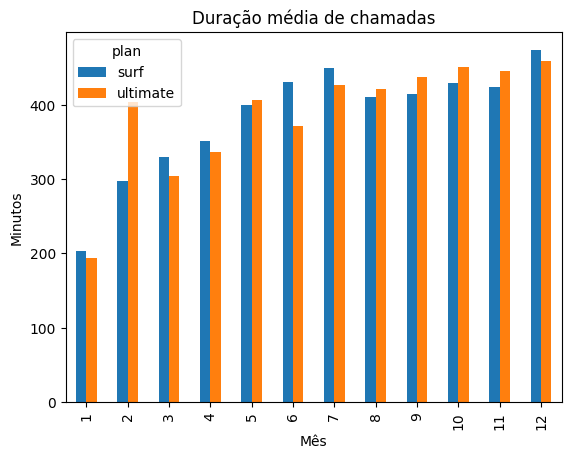

In [ ]:

# Compare a duração média das chamadas de cada plano para cada mês. Crie um gráfico de barras para visualizar o resultado.
mean_call_id_month = date_id_month.groupby(['month','plan'])['duration'].mean().unstack()
mean_call_id_month.plot(kind='bar',
                       title = 'Duração média de chamadas',
                       xlabel = 'Mês',ylabel = 'Minutos')


Text(0, 0.5, 'Usuários')

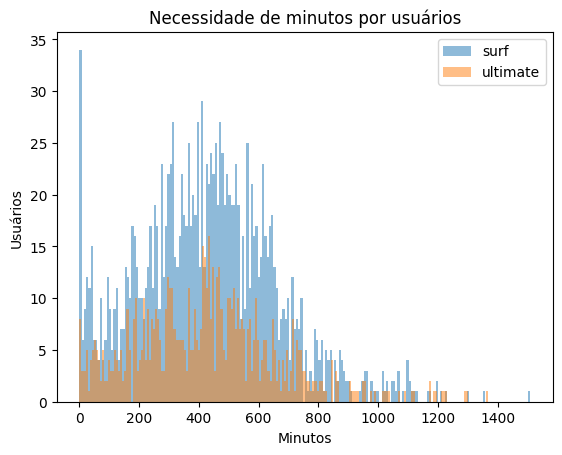

In [ ]:

# Compare o número de minutos que os usuários de cada plano necessitam a cada mês. Construa um histograma.

minutes_surf_id_month = date_id_month[date_id_month['plan'] == 'surf']
minutes_ultimate_id_month = date_id_month[date_id_month['plan'] == 'ultimate']

surf_minutes_need_id_month = minutes_surf_id_month.groupby(['user_id','month'])['duration'].sum()
ultimate_minutes_need_id_month = minutes_ultimate_id_month.groupby(['user_id','month'])['duration'].sum()


surf_minutes_need_id_month.plot(kind = 'hist', alpha = 0.5,
                          bins = 200, label = 'surf',
                               title = 'Necessidade de minutos por usuários')
ultimate_minutes_need_id_month.plot(kind = 'hist', alpha = 0.5,
                         bins = 200, label = 'ultimate')
plt.legend ()
plt.xlabel ('Minutos')
plt.ylabel ('Usuários')





[Calcule a média e a variância da duração das chamadas para refletir se os usuários de cada plano possuem comportamentos diferentes sobre as chamadas.]

In [ ]:
# Calcule a média e a variância da duração mensal das chamadas

var_call = date_id_month.groupby(['month','plan'])['duration'].var()

print(var_call)
print(mean_call_id_month)

month  plan    
1      surf        15842.000000
       ultimate    16572.333333
2      surf        52226.500000
       ultimate    76889.476190
3      surf        35809.363636
       ultimate    61984.931818
4      surf        50866.743265
       ultimate    34888.928571
5      surf        59754.219754
       ultimate    43841.046798
6      surf        45592.628436
       ultimate    42503.563367
7      surf        61005.099725
       ultimate    72563.374635
8      surf        54344.645963
       ultimate    53645.506640
9      surf        46595.958656
       ultimate    57070.464569
10     surf        52278.664056
       ultimate    54261.910512
11     surf        51607.021602
       ultimate    60593.222847
12     surf        63629.518918
       ultimate    62503.783400
Name: duration, dtype: float64
plan         surf    ultimate
month                        
1      203.000000  193.500000
2      297.000000  403.142857
3      330.000000  304.250000
4      351.540000  336.857143
5    

<AxesSubplot:>

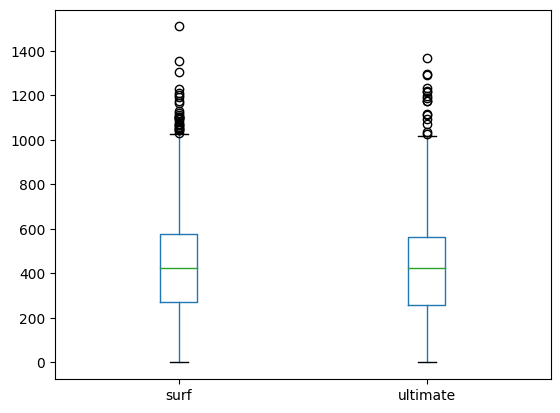

In [ ]:
# Faça um diagrama de caixa para visualizar a distribuição da duração mensal das chamadas
minutes_need_id_month_plan = date_id_month.groupby(['user_id','month','plan'])['duration'].sum().unstack()
minutes_need_id_month_plan.plot(kind = 'box')



No primeiro gráfico podemos notar que a média de ligações nos 2 planos são bem parecidas, as duas tem um primeiro mês mais fraco e vão crescendo ao longo do ano. Vimos tamém que temos vários usuáros que não fazem ligação e depois percebemos uma distribuição normal um pouco para a esquerda, com a maioria dos usuários utilizando de 300 a 500 minutos. E no gráfico de box, podemos perceber também números bem parecidos nos valores mínimos, máximos e no 1, 2 e 3 quartil.

### Mensagens

<AxesSubplot:title={'center':'Média de menssagens por plano'}, xlabel='Mes', ylabel='Mensagens'>

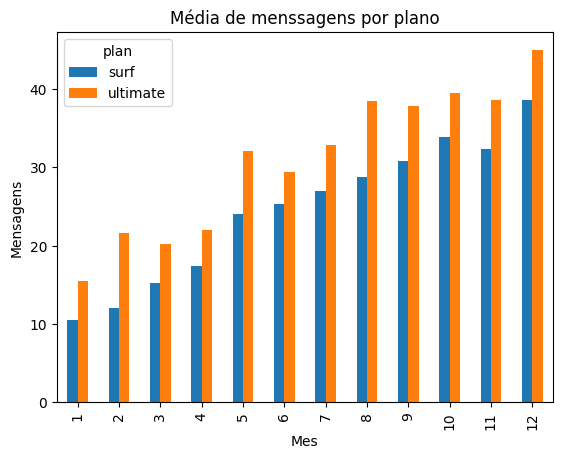

In [ ]:
# Compare o número de mensagens que os usuários de cada plano costumam enviar a cada mês
sum_message_id_month = date_id_month.groupby(['month','plan'])['message_count'].mean().unstack()

sum_message_id_month.plot(kind = 'bar', title = 'Média de menssagens por plano',
                         xlabel = 'Mes', ylabel = 'Mensagens')


Text(0, 0.5, 'Usuários')

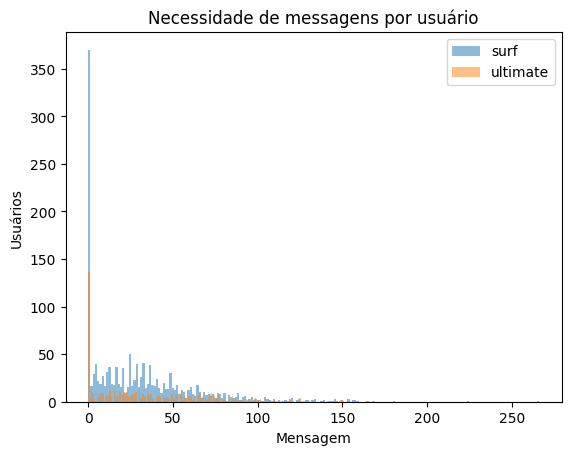

In [ ]:

surf_message_id_month = date_id_month[date_id_month['plan'] == 'surf']
ultimate_message_id_month = date_id_month[date_id_month['plan'] == 'ultimate']

surf_sum_message_id_month = surf_message_id_month.groupby(['month','user_id'])['message_count'].sum()
ultimate_sum_message_id_month = ultimate_message_id_month.groupby(['month','user_id'])['message_count'].sum()

surf_sum_message_id_month.plot(kind='hist', alpha = 0.5,
                              bins = 200, label = 'surf',
                              title = 'Necessidade de messagens por usuário')
ultimate_sum_message_id_month.plot(kind='hist', alpha = 0.5,
                              bins = 200, label = 'ultimate')

plt.legend()
plt.xlabel('Mensagem')
plt.ylabel('Usuários')

plan        surf   ultimate
month                      
1      10.500000  15.500000
2      12.000000  21.571429
3      15.260870  20.250000
4      17.400000  22.047619
5      24.012987  32.103448
6      25.298969  29.340426
7      27.033058  32.830508
8      28.777778  38.478873
9      30.762887  37.895349
10     33.839662  39.443396
11     32.385159  38.606299
12     38.600629  45.006623
month  plan    
1      surf         220.500000
       ultimate     313.666667
2      surf         386.000000
       ultimate     478.285714
3      surf         346.565217
       ultimate     654.386364
4      surf         501.591837
       ultimate     544.147619
5      surf         847.197198
       ultimate    1297.310345
6      surf         914.920103
       ultimate     857.620722
7      surf         923.915565
       ultimate     960.488019
8      surf        1029.515528
       ultimate    1196.367404
9      surf        1003.829496
       ultimate    1050.918331
10     surf        1275.465708
   

<AxesSubplot:>

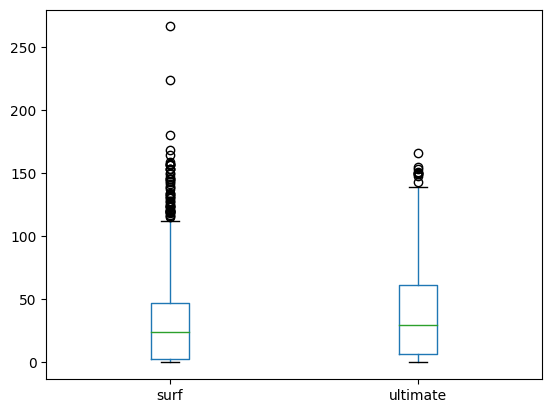

In [ ]:

var_message_id_month = date_id_month.groupby(['month','plan'])['message_count'].var()
sum_message_id_month = date_id_month.groupby(['month','plan'])['message_count'].mean().unstack()
std_message_id_month = date_id_month.groupby(['month','plan'])['message_count'].std().unstack()


print(sum_message_id_month)
print(var_message_id_month)
print(std_message_id_month)
print()
comparar_message = pd.concat([surf_sum_message_id_month,ultimate_sum_message_id_month], axis = 1, keys =['surf','ultimate'])
comparar_message.plot(kind = 'box')





Podemos notar uma utilização maior de mensagens dos usuários do plano ultimate do que do surf. Existe tambpem um aumento da média ao logo que o ano avança.

### Internet

In [ ]:
# Compare a quantidade de tráfego de internet consumido pelos usuários por plano

<AxesSubplot:title={'center':'Média de GB por plano'}, xlabel='Mes', ylabel='GB'>

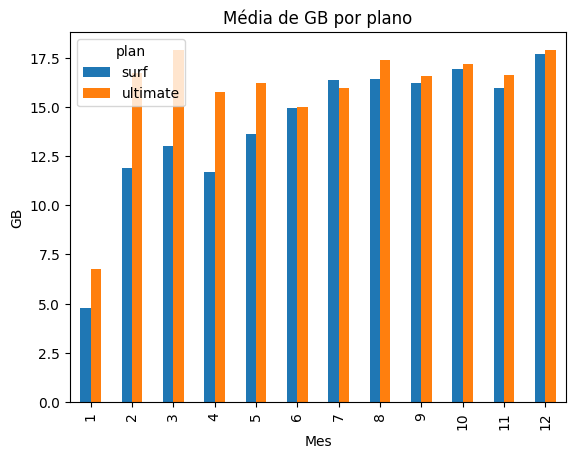

In [ ]:
sum_session_id_month = date_id_month.groupby(['month','plan'])['gb_used'].mean().unstack()

sum_session_id_month.plot(kind = 'bar', title = 'Média de GB por plano',
                         xlabel = 'Mes', ylabel = 'GB')


month  plan    
1      surf         4.760605
       ultimate     6.755950
2      surf        11.893402
       ultimate    16.727352
3      surf        13.032656
       ultimate    17.892108
4      surf        11.703323
       ultimate    15.743803
5      surf        13.609722
       ultimate    16.234846
6      surf        14.942900
       ultimate    14.978439
7      surf        16.390235
       ultimate    15.961664
8      surf        16.401691
       ultimate    17.397188
9      surf        16.202570
       ultimate    16.572138
10     surf        16.905601
       ultimate    17.199759
11     surf        15.956303
       ultimate    16.634458
12     surf        17.707490
       ultimate    17.893742
Name: gb_used, dtype: float64
month  plan    
1      surf         17.394976
       ultimate     15.635216
2      surf         41.649779
       ultimate     35.904976
3      surf         65.084035
       ultimate    133.837858
4      surf         56.309643
       ultimate     84.332091
5 

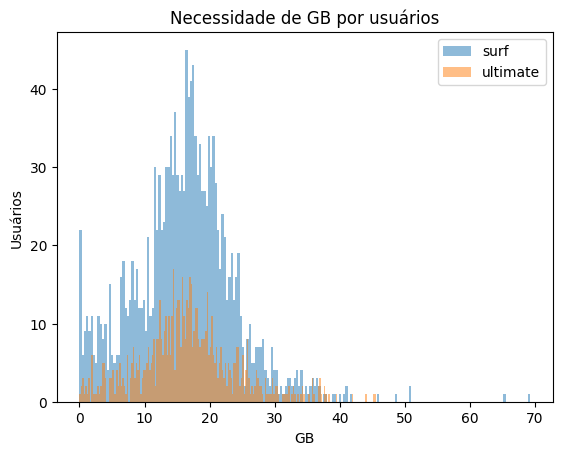

In [ ]:
surf_session_id_month = date_id_month[date_id_month['plan']== 'surf']
ultimate_session_id_month = date_id_month[date_id_month['plan']== 'ultimate']

surf_sum_session_id_month = surf_session_id_month.groupby(['month','user_id'])['gb_used'].sum()
ultimate_sum_session_id_month = ultimate_session_id_month.groupby(['month','user_id'])['gb_used'].sum()

surf_sum_session_id_month.plot(kind = 'hist', alpha = 0.5,
                              bins = 200, label = 'surf',
                              title = 'Necessidade de GB por usuários')

ultimate_sum_session_id_month.plot(kind = 'hist', alpha = 0.5,
                              bins = 200, label = 'ultimate')
plt.legend()
plt.xlabel('GB')
plt.ylabel('Usuários')


mean_session_per_client = date_id_month.groupby(['month','plan'])['gb_used'].mean()
var_session_per_client = date_id_month.groupby(['month','plan'])['gb_used'].var()
std_session_client = date_id_month.groupby(['month','plan'])['gb_used'].std()

print(mean_session_per_client)
print(var_session_per_client)
print(std_session_client)




Podemos notar uma utilização maior de GB dos usuários do plano ultimate do que do surf. Existe tambpem um aumento da média ao logo que o ano avança.

## Receita

In [ ]:
sum_usd_id_month = date_id_month.groupby(['month','plan'])['usd_per_client'].mean().unstack()


<AxesSubplot:title={'center':'Receita média do usuário por plano'}, xlabel='Mes', ylabel='USD'>

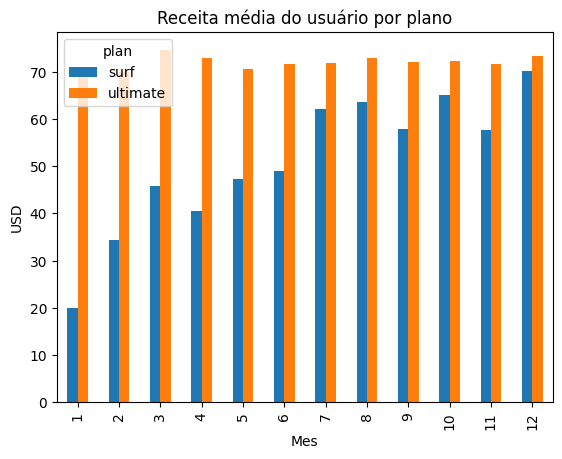

In [ ]:
sum_usd_id_month.plot(kind = 'bar', title = 'Receita média do usuário por plano',
                         xlabel = 'Mes', ylabel = 'USD')

In [ ]:

mean_usd_per_client = date_id_month.groupby(['month','plan'])['usd_per_client'].mean()
var_usd_per_client = date_id_month.groupby(['month','plan'])['usd_per_client'].var()
std_usd_per_client = date_id_month.groupby(['month','plan'])['usd_per_client'].std()

print(mean_usd_per_client)
print(var_usd_per_client)
print(std_usd_per_client)



month  plan    
1      surf        20.000000
       ultimate    70.000000
2      surf        34.260000
       ultimate    70.000000
3      surf        45.792609
       ultimate    74.666667
4      surf        40.458600
       ultimate    73.000000
5      surf        47.240130
       ultimate    70.724138
6      surf        48.935155
       ultimate    71.638298
7      surf        62.226529
       ultimate    71.898305
8      surf        63.576728
       ultimate    72.859155
9      surf        57.952320
       ultimate    72.034884
10     surf        65.051097
       ultimate    72.311321
11     surf        57.633569
       ultimate    71.708661
12     surf        70.108270
       ultimate    73.291391
Name: usd_per_client, dtype: float64
month  plan    
1      surf           0.000000
       ultimate       0.000000
2      surf         429.928400
       ultimate       0.000000
3      surf        1507.703438
       ultimate     145.515152
4      surf        1196.921771
       ultimate   


Podemos notar que a receita média dos usuários do plano ultimate é estável e alta o ano todo, enquanto a receita média do plano surf, começa bem pequena no inicio do ano e vai aumentando gradativamente até o final do ano e mesmo assim fica abaixo do plano ultimate em dezembro

## Teste hipóteses estatísticas



Iremos fazer o teste de hipotese sobre a igualdade das médias de duas populações e usar o t-teste para amostras independentes, pois vamos comparar 2 populações diferentes,os ousuários do plano ultimate e os usuários do plano surf,  e vamos usar o valor de 0.05 de alpha para obter uma significancia satisfatória. Onde H0 é "Não há diferença na receita média dos usuários" e H1 é "Há diferença na receita média dos usuários"

In [ ]:
# Teste as hipóteses


alpha = 0.05
results = st.ttest_ind(date_id_month[date_id_month['plan'] == 'surf']['usd_per_client'],date_id_month[date_id_month['plan'] == 'ultimate']['usd_per_client'])

print('valor-p: ', results.pvalue)
if results.pvalue < alpha:
    print('Rejeitamos a hipótese nula')
else:
    print('Não rejeitamos a hipótese nula')


valor-p:  9.470478215100305e-09
Rejeitamos a hipótese nula


[Teste a hipótese de que a receita média dos usuários da área de NY-NJ difere dos usuários das demais regiões.]



Iremos fazer o teste de hipotese sobre a igualdade das médias de duas populações e usar o t-teste para amostras independentes, pois vamos comparar 2 populações diferentes,os ousuários ne NY-NJ e o restante dos usuários do país,  e vamos usar o valor de 0.05 de alpha para obter uma significancia satisfatória. Onde H0 é "Não há diferença na receita média dos usuários" e H1 é "Há diferença na receita média dos usuários"

In [ ]:
# Teste as hipóteses
alpha = 0.05
results = st.ttest_ind(date_id_month[date_id_month['city'] == 'New York-Newark-Jersey City, NY-NJ-PA MSA']['usd_per_client'],
                       date_id_month[date_id_month['city'] != 'New York-Newark-Jersey City, NY-NJ-PA MSA']['usd_per_client'])

print('valor-p: ', results.pvalue)
if results.pvalue < alpha:
    print('Rejeitamos a hipótese nula')
else:
    print('Não rejeitamos a hipótese nula')


valor-p:  0.04076784279879048
Rejeitamos a hipótese nula


## Conclusão geral


Começamos preparando os dados para conseguir fazer uma análise correta, identificamos possiveis valores ausentes e duplicados e ajustamos. Alteramos os tipos da dados que estavam em desacordo também. Com os dados corretos fizemos as análises gráfica e percebemso que os valores de mensagens, ligações e internet aumentavam durante o ano, mas sem muita diferença entre os 2 planos e isso repercurtiu bem na receita. Notamos que a média de receita por usuário do plano ultimate e maior e mais estável que a do plano surf, apesar dos clientes do plano surf gastarem um valor maior com o excedente, a estabilidade ao lonog do ano e o valor do plano inicial do ultimate (USD70.00) compensam esse gasto excedente. Podemos notar isso no teste de hipotese onde rejeitamos a hipótese nula(H0). No segundo teste de hipótese podemos concluir que a receita média dos usuário de NY-NJ é diferente do resto do país.
